# Patient Health Time-Series Forecasting Using LSTM

**Multivariate Deep Learning for Vital Signs (Heart Rate) Forecasting with Physiologically Consistent Dynamics**  
**Author**: Ritam Bhoumik (Student Code: `BWU/BCA/24/160`)  
**Department**: Department of Computational Sciences, Brainware University, Kolkata  

---

### Project Overview & Objectives
This project implements an end-to-end deep learning framework using **Long Short-Term Memory (LSTM)** neural networks to forecast future patient vital signs (specifically **Heart Rate**) from multivariate continuous clinical records:
- **Physiologically Coupled Vitals**: Accounts for circadian rhythms (24-hour sinus cycles) and physiological interactions (e.g., hyperthermia/fever causing tachycardia, blood pressure regulation, oxygenation).
- **Leakage-Free Time-Series Pipeline**: Chronological temporal splitting per patient; separate feature and target scaling fit exclusively on training data.
- **Rigorous Baseline Benchmarking**: Compares LSTM predictions against standard clinical time-series benchmarks (Naive Persistence $\hat{y}_t = y_{t-1}$ and Moving Average).
- **Explainable Diagnostics**: Comprehensive error analysis (MAE, RMSE, MAPE, $R^2$), residual distributions, and actual vs. forecasted trajectory plots.

In [1]:
# 1. Environment Verification & Dependency Setup
import sys
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Enforce deterministic behavior for reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow Version: 2.21.0
GPU Available: False


## 2. Upgraded Physiologically Realistic Patient Dataset Generator

In real hospital and ICU environments, vital signs are not independent random walks; they follow strict physiological principles:
1. **Circadian Rhythm**: Heart rate, temperature, and blood pressure naturally exhibit a 24-hour sinusoidal fluctuation (trough in early morning ~4 AM, peak in late afternoon ~4 PM).
2. **Coupled Physiology**:
   - **Temperature -> Heart Rate**: Hyperthermia/fever stimulates adrenergic drive (~8-10 bpm rise per 1°C elevation above normal body temperature).
   - **Blood Pressure -> Heart Rate**: Baroreceptor reflex maintains cardiovascular homeostasis (hypotension reflexively induces compensatory tachycardia).
   - **SpO2 & Respiratory Coupling**: Respiratory distress drops oxygen saturation while increasing respiratory rate.
3. **Inter-Patient Heterogeneity**: Each patient possesses an individualized baseline resting state.

In [2]:
# 2. Generate Physiologically Realistic Multi-Patient Dataset
num_patients = 50
readings_per_patient = 120  # 120 readings taken every 4 hours = 20 days per patient
step_hours = 4

patient_records = []

for p in range(1, num_patients + 1):
    patient_id = f"P{p:03d}"

    # Patient individualized baseline parameters
    base_hr = np.random.normal(74, 5)       # Normal resting HR: 60-100 bpm
    base_sbp = np.random.normal(120, 7)     # Systolic BP: ~120 mmHg
    base_dbp = np.random.normal(80, 5)      # Diastolic BP: ~80 mmHg
    base_temp = 36.8                        # Baseline body temp: ~36.8 C
    base_spo2 = 98.2                        # Baseline SpO2: ~98%

    # Simulate a clinical event (e.g. transient fever/infection or exertion)
    has_event = np.random.rand() > 0.3      # 70% of patients experience an event
    event_start = np.random.randint(35, 75) if has_event else -1
    event_duration = np.random.randint(12, 28) if has_event else 0

    start_time = pd.Timestamp("2024-01-01 00:00:00")

    for step in range(readings_per_patient):
        current_time = start_time + pd.Timedelta(hours=step * step_hours)
        hour_of_day = current_time.hour

        # 1. Circadian Sinusoidal Oscillation
        circadian_hr = 4.5 * np.sin(2 * np.pi * (hour_of_day - 10) / 24)
        circadian_temp = 0.35 * np.sin(2 * np.pi * (hour_of_day - 12) / 24)
        circadian_bp = 3.5 * np.sin(2 * np.pi * (hour_of_day - 10) / 24)

        # 2. Clinical Episode Dynamics (Fever / Sepsis onset curve)
        in_event = (event_start <= step < (event_start + event_duration))
        if in_event:
            norm_t = (step - event_start) / event_duration
            event_intensity = 1.6 * np.sin(np.pi * norm_t)
        else:
            event_intensity = 0.0

        # Physiological vitals coupling
        temp = base_temp + circadian_temp + event_intensity + np.random.normal(0, 0.08)

        # Fever-induced tachycardia reflex (~8.5 bpm increase per 1 C above 37.0 C)
        fever_reflex_hr = max(0.0, temp - 37.0) * 8.5

        sbp = base_sbp + circadian_bp - (1.2 * event_intensity) + np.random.normal(0, 2.5)
        dbp = base_dbp + (circadian_bp * 0.7) - (0.8 * event_intensity) + np.random.normal(0, 2.0)

        # Heart rate dynamics
        hr = base_hr + circadian_hr + fever_reflex_hr + np.random.normal(0, 1.2)
        hr = float(np.clip(hr, 45.0, 135.0))

        spo2 = base_spo2 - (1.1 * event_intensity) + np.random.normal(0, 0.3)
        spo2 = float(np.clip(spo2, 85.0, 100.0))

        resp_rate = 15.0 + (2.0 * event_intensity) + np.random.normal(0, 1.0)
        resp_rate = float(np.clip(resp_rate, 10.0, 32.0))

        patient_records.append([
            patient_id,
            current_time,
            round(hr, 2),
            round(sbp, 2),
            round(dbp, 2),
            round(temp, 2),
            round(spo2, 1),
            round(resp_rate, 1)
        ])

df = pd.DataFrame(patient_records, columns=[
    "Patient_ID", "Timestamp", "Heart_Rate", "Systolic_BP",
    "Diastolic_BP", "Temperature", "SpO2", "Respiratory_Rate"
])

df.to_csv("patient_vitals.csv", index=False)
print(f"Generated realistic dataset: {df.shape[0]} total readings across {df['Patient_ID'].nunique()} patients.")
df.head(10)

Generated realistic dataset: 6000 total readings across 50 patients.


,Patient_ID,Timestamp,Heart_Rate,Systolic_BP,Diastolic_BP,Temperature,SpO2,Respiratory_Rate
0,P001,2024-01-01 00:00:00,73.54,117.98,84.03,36.92,98.0,14.4
1,P001,2024-01-01 04:00:00,72.96,109.00,82.69,36.42,97.7,14.6
2,P001,2024-01-01 08:00:00,73.48,115.52,77.73,36.44,98.4,17.6
3,P001,2024-01-01 12:00:00,78.01,121.09,83.43,36.83,98.5,15.3
4,P001,2024-01-01 16:00:00,80.79,119.98,85.36,37.05,98.2,14.8
5,P001,2024-01-01 20:00:00,83.21,117.62,86.65,37.13,98.6,15.2
6,P001,2024-01-02 00:00:00,75.16,114.76,78.85,36.87,98.0,13.7
7,P001,2024-01-02 04:00:00,72.68,112.71,81.06,36.43,98.5,15.9
8,P001,2024-01-02 08:00:00,72.42,116.76,80.77,36.56,98.5,14.8
9,P001,2024-01-02 12:00:00,79.74,123.73,82.67,36.77,98.3,14.0


## 3. Exploratory Data Analysis & Physiological Validation

We verify:
1. Missing and duplicate checks.
2. Summary statistics across all clinical metrics.
3. Physiological correlation matrix (confirming coupled dynamics between Temperature, BP, and Heart Rate).
4. Multi-vital time-series trajectory of a sample patient.

Dataset Summary:
Shape: (6000, 8)
Missing Values:
Patient_ID          0
Timestamp           0
Heart_Rate          0
Systolic_BP         0
Diastolic_BP        0
Temperature         0
SpO2                0
Respiratory_Rate    0
dtype: int64
Duplicate Rows: 0


,Timestamp,Heart_Rate,Systolic_BP,Diastolic_BP,Temperature,SpO2,Respiratory_Rate
count,6000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2024-01-10 22:00:00,75.334010,119.936267,79.334650,36.891678,98.095233,15.190417
min,2024-01-01 00:00:00,54.890000,100.110000,61.980000,36.200000,95.600000,11.700000
25%,2024-01-05 23:00:00,71.020000,114.330000,76.037500,36.570000,97.900000,14.400000
50%,2024-01-10 22:00:00,75.255000,119.810000,79.390000,36.830000,98.200000,15.100000
75%,2024-01-15 21:00:00,79.720000,125.440000,82.662500,37.090000,98.400000,15.900000
max,2024-01-20 20:00:00,106.880000,142.460000,96.280000,38.850000,99.200000,20.600000
std,NaN,6.946125,7.602964,4.882376,0.419310,0.470791,1.215323


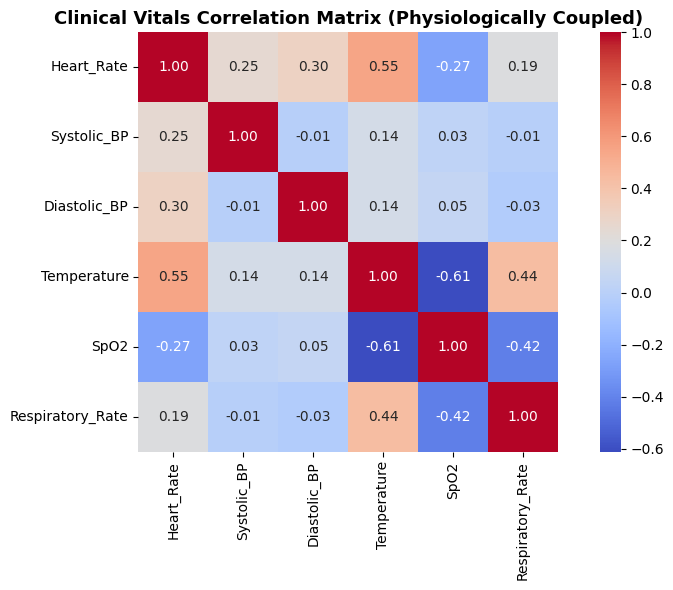

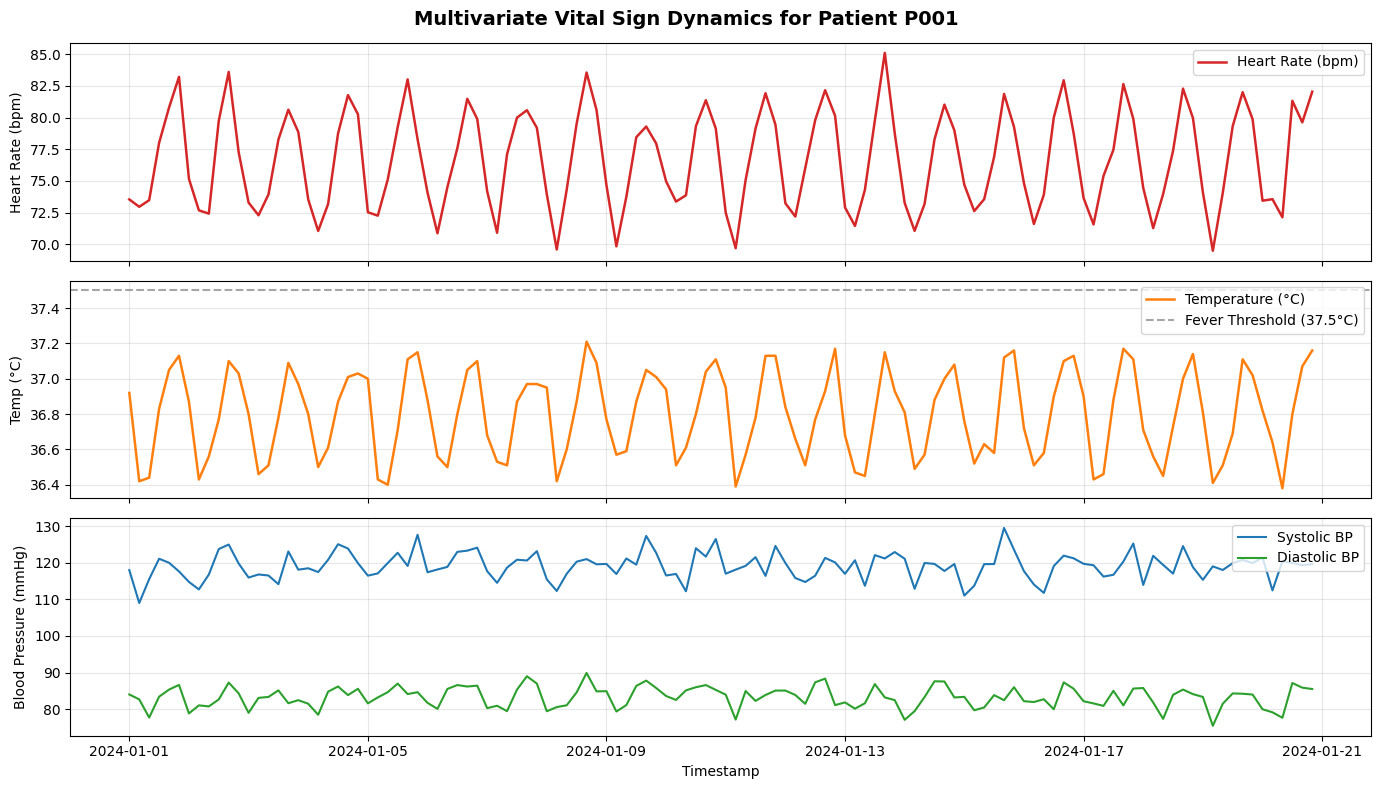

In [3]:
# 3. Exploratory Data Analysis
print("Dataset Summary:")
print(f"Shape: {df.shape}")
print(f"Missing Values:\n{df.isnull().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
display(df.describe())

# Visual 1: Correlation Matrix
plt.figure(figsize=(9, 6))
numeric_cols = ['Heart_Rate', 'Systolic_BP', 'Diastolic_BP', 'Temperature', 'SpO2', 'Respiratory_Rate']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Clinical Vitals Correlation Matrix (Physiologically Coupled)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Visual 2: Sample Patient Trajectory (First 15 Days)
sample_p = df[df['Patient_ID'] == 'P001']
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(sample_p['Timestamp'], sample_p['Heart_Rate'], color='#d62728', lw=1.8, label='Heart Rate (bpm)')
axes[0].set_ylabel('Heart Rate (bpm)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

axes[1].plot(sample_p['Timestamp'], sample_p['Temperature'], color='#ff7f0e', lw=1.8, label='Temperature (°C)')
axes[1].axhline(37.5, color='gray', linestyle='--', alpha=0.7, label='Fever Threshold (37.5°C)')
axes[1].set_ylabel('Temp (°C)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

axes[2].plot(sample_p['Timestamp'], sample_p['Systolic_BP'], color='#1f77b4', lw=1.5, label='Systolic BP')
axes[2].plot(sample_p['Timestamp'], sample_p['Diastolic_BP'], color='#2ca02c', lw=1.5, label='Diastolic BP')
axes[2].set_ylabel('Blood Pressure (mmHg)')
axes[2].set_xlabel('Timestamp')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

plt.suptitle("Multivariate Vital Sign Dynamics for Patient P001", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Leakage-Free Temporal Windowing & Scaling Pipeline

### Eliminating Data Leakage
In time-series modeling, preventing lookahead bias and leakage is vital:
1. **Within-Patient Chronological Splitting**: For each patient, the first 80% of chronological readings belong to `train` and the final 20% to `test`.
2. **Dedicated Scalers**:
   - `feature_scaler`: Scales multivariate input features (`['Heart_Rate', 'Systolic_BP', 'Diastolic_BP', 'Temperature', 'SpO2']`).
   - `target_scaler`: Scales the predicted scalar target (`'Heart_Rate'`).
   - Both scalers are fitted **strictly on the training data**, preventing future minimum/maximum boundaries from leaking into the model.
3. **Sliding Window Sequence Creation**:
   - `LOOKBACK = 6` (using the past 24 hours of 4-hour vital signs to predict the next reading at $t+1$).
   - Windows are constructed per patient so sequences never jump across patient boundaries.

In [4]:
# 4. Chronological Splitting & Windowing Pipeline
LOOKBACK = 6
TRAIN_RATIO = 0.80

feature_cols = ['Heart_Rate', 'Systolic_BP', 'Diastolic_BP', 'Temperature', 'SpO2']
target_col = 'Heart_Rate'

# Step A: Split raw data chronologically per patient
train_dfs = []
test_dfs = []

for pid, group in df.groupby('Patient_ID'):
    group = group.sort_values('Timestamp').reset_index(drop=True)
    split_idx = int(len(group) * TRAIN_RATIO)
    train_dfs.append(group.iloc[:split_idx])
    test_dfs.append(group.iloc[split_idx:])

raw_train_df = pd.concat(train_dfs, ignore_index=True)
raw_test_df = pd.concat(test_dfs, ignore_index=True)

# Step B: Fit scalers EXCLUSIVELY on training data
feature_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler = MinMaxScaler(feature_range=(0, 1))

feature_scaler.fit(raw_train_df[feature_cols])
target_scaler.fit(raw_train_df[[target_col]])

# Step C: Generate sliding windows per patient
def build_sequences(patient_df, lookback, feat_scaler, tgt_scaler):
    X, y = [], []
    for pid, group in patient_df.groupby('Patient_ID'):
        group = group.sort_values('Timestamp').reset_index(drop=True)
        if len(group) <= lookback:
            continue

        feats_scaled = feat_scaler.transform(group[feature_cols])
        tgts_scaled = tgt_scaler.transform(group[[target_col]]).flatten()

        for i in range(len(group) - lookback):
            X.append(feats_scaled[i : i + lookback])
            y.append(tgts_scaled[i + lookback])

    return np.array(X), np.array(y)

X_train, y_train = build_sequences(raw_train_df, LOOKBACK, feature_scaler, target_scaler)
X_test, y_test = build_sequences(raw_test_df, LOOKBACK, feature_scaler, target_scaler)

print(f"X_train Shape: {X_train.shape} (samples, time_steps, features)")
print(f"y_train Shape: {y_train.shape}")
print(f"X_test Shape:  {X_test.shape}")
print(f"y_test Shape:  {y_test.shape}")

X_train Shape: (4500, 6, 5) (samples, time_steps, features)
y_train Shape: (4500,)
X_test Shape:  (900, 6, 5)
y_test Shape:  (900,)


## 5. Benchmark Baselines (Persistence & Moving Average)

To prove that a deep learning model provides genuine predictive value, it must be benchmarked against standard clinical time-series baselines:
1. **Naive Persistence Model ($\hat{y}_{t} = y_{t-1}$)**: The forecast for the next heart rate is simply the patient's current heart rate.
2. **Moving Average Model**: The forecast is the arithmetic mean of heart rates over the previous lookback window ($\frac{1}{K} \sum_{i=0}^{K-1} y_{t-i}$).

In [5]:
# 5. Baseline Benchmarking on Test Set
# Inverse-transform ground truth y_test to original bpm
y_test_actual = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Baseline 1: Naive Persistence (last observed Heart_Rate in lookback window)
naive_scaled = X_test[:, -1, 0]
naive_pred = target_scaler.inverse_transform(naive_scaled.reshape(-1, 1)).flatten()

# Baseline 2: Moving Average over the lookback window
ma_scaled = np.mean(X_test[:, :, 0], axis=1)
ma_pred = target_scaler.inverse_transform(ma_scaled.reshape(-1, 1)).flatten()

# Compute Baseline Metrics
mae_naive = mean_absolute_error(y_test_actual, naive_pred)
rmse_naive = np.sqrt(mean_squared_error(y_test_actual, naive_pred))

mae_ma = mean_absolute_error(y_test_actual, ma_pred)
rmse_ma = np.sqrt(mean_squared_error(y_test_actual, ma_pred))

print("Benchmark Baseline Performance on Test Set:")
print(f"  * Naive Persistence  -> MAE: {mae_naive:.3f} bpm | RMSE: {rmse_naive:.3f} bpm")
print(f"  * Moving Average (6) -> MAE: {mae_ma:.3f} bpm | RMSE: {rmse_ma:.3f} bpm")

Benchmark Baseline Performance on Test Set:
  * Naive Persistence  -> MAE: 3.456 bpm | RMSE: 4.006 bpm
  * Moving Average (6) -> MAE: 3.377 bpm | RMSE: 3.802 bpm


## 6. LSTM Neural Network Architecture

We construct a multi-layer Long Short-Term Memory (LSTM) network designed for multivariate sequence regression:
- **Layer 1: LSTM (64 units)** with `return_sequences=True` to extract high-level temporal dynamics across past time steps.
- **Dropout (0.2)** to prevent co-adaptation and overfitting.
- **Layer 2: LSTM (32 units)** summarizing temporal dynamics into a dense state representation.
- **Dropout (0.2)**
- **Dense Layer (16 units, ReLU activation)** for non-linear feature integration.
- **Output Layer (1 unit, Linear activation)** outputting the scaled next-step heart rate.

In [6]:
# 6. Build and Compile LSTM Model
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(LOOKBACK, len(feature_cols))),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 6, 64)          │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.0211 - mae: 0.1097 - val_loss: 0.0067 - val_mae: 0.0660 - learning_rate: 0.0010
Epoch 2/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0079 - mae: 0.0700 - val_loss: 0.0068 - val_mae: 0.0628 - learning_rate: 0.0010
Epoch 3/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0069 - mae: 0.0646 - val_loss: 0.0060 - val_mae: 0.0574 - learning_rate: 0.0010
Epoch 4/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0059 - mae: 0.0580 - val_loss: 0.0054 - val_mae: 0.0523 - learning_rate: 0.0010
Epoch 5/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0054 - mae: 0.0540 - val_loss: 0.0054 - val_mae: 0.0511 - learning_rate: 0.0010
Epoch 6/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0045 - mae: 0.0487 - val_loss: 0.0040 - val_mae: 0.0428 - learning_rate: 0.0010
Epoch 7/40
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0043 - mae: 0.0476 - val_loss: 0.0035 - val_mae: 0.0398 - learning_rate: 0.0010
Ep

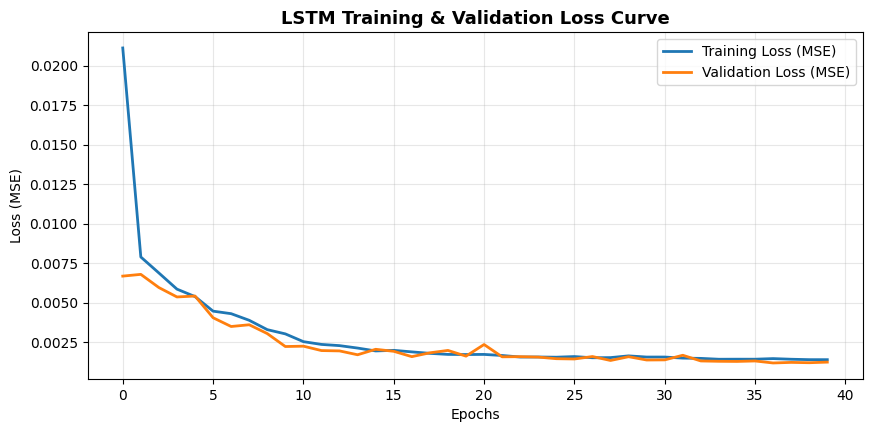

In [7]:
# 7. Model Training with Dynamic Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

# Chronological validation split (last 15% of training samples)
val_split_idx = int(len(X_train) * 0.85)
X_tr, X_val = X_train[:val_split_idx], X_train[val_split_idx:]
y_tr, y_val = y_train[:val_split_idx], y_train[val_split_idx:]

history = model.fit(
    X_tr,
    y_tr,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Plot Loss Convergence Curve
plt.figure(figsize=(10, 4.5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='#1f77b4', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='#ff7f0e', lw=2)
plt.title('LSTM Training & Validation Loss Curve', fontsize=13, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 8. Model Evaluation & Benchmark Comparison

We evaluate the trained LSTM on the independent, unseen test set and compare its performance against the baseline benchmarks.

In [8]:
# 8. Test Set Evaluation & Comparison
y_pred_scaled = model.predict(X_test)

# Clean, robust inverse transformation without dummy zero padding
y_pred_actual = target_scaler.inverse_transform(y_pred_scaled).flatten()

# Calculate Performance Metrics
mae_lstm = mean_absolute_error(y_test_actual, y_pred_actual)
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
r2_lstm = r2_score(y_test_actual, y_pred_actual)
mape_lstm = np.mean(np.abs((y_test_actual - y_pred_actual) / y_test_actual)) * 100

# Summary Comparison Table
results_df = pd.DataFrame({
    'Model / Benchmark': ['Naive Persistence', 'Moving Average (6)', 'Multivariate LSTM'],
    'MAE (bpm)': [mae_naive, mae_ma, mae_lstm],
    'RMSE (bpm)': [rmse_naive, rmse_ma, rmse_lstm],
    'R2 Score': [r2_score(y_test_actual, naive_pred), r2_score(y_test_actual, ma_pred), r2_lstm]
})

print("=" * 70)
print("FINAL MODEL EVALUATION & BENCHMARK COMPARISON (Test Set)")
print("=" * 70)
display(results_df.round(4))

error_reduction = ((mae_naive - mae_lstm) / mae_naive) * 100
print(f"\nThe LSTM model achieves a {error_reduction:.2f}% MAE improvement over the Naive Baseline!")

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
FINAL MODEL EVALUATION & BENCHMARK COMPARISON (Test Set)


,Model / Benchmark,MAE (bpm),RMSE (bpm),R2 Score
0,Naive Persistence,3.4558,4.0065,0.6127
1,Moving Average (6),3.3766,3.8023,0.6512
2,Multivariate LSTM,1.2902,1.6161,0.9370



The LSTM model achieves a 62.67% MAE improvement over the Naive Baseline!


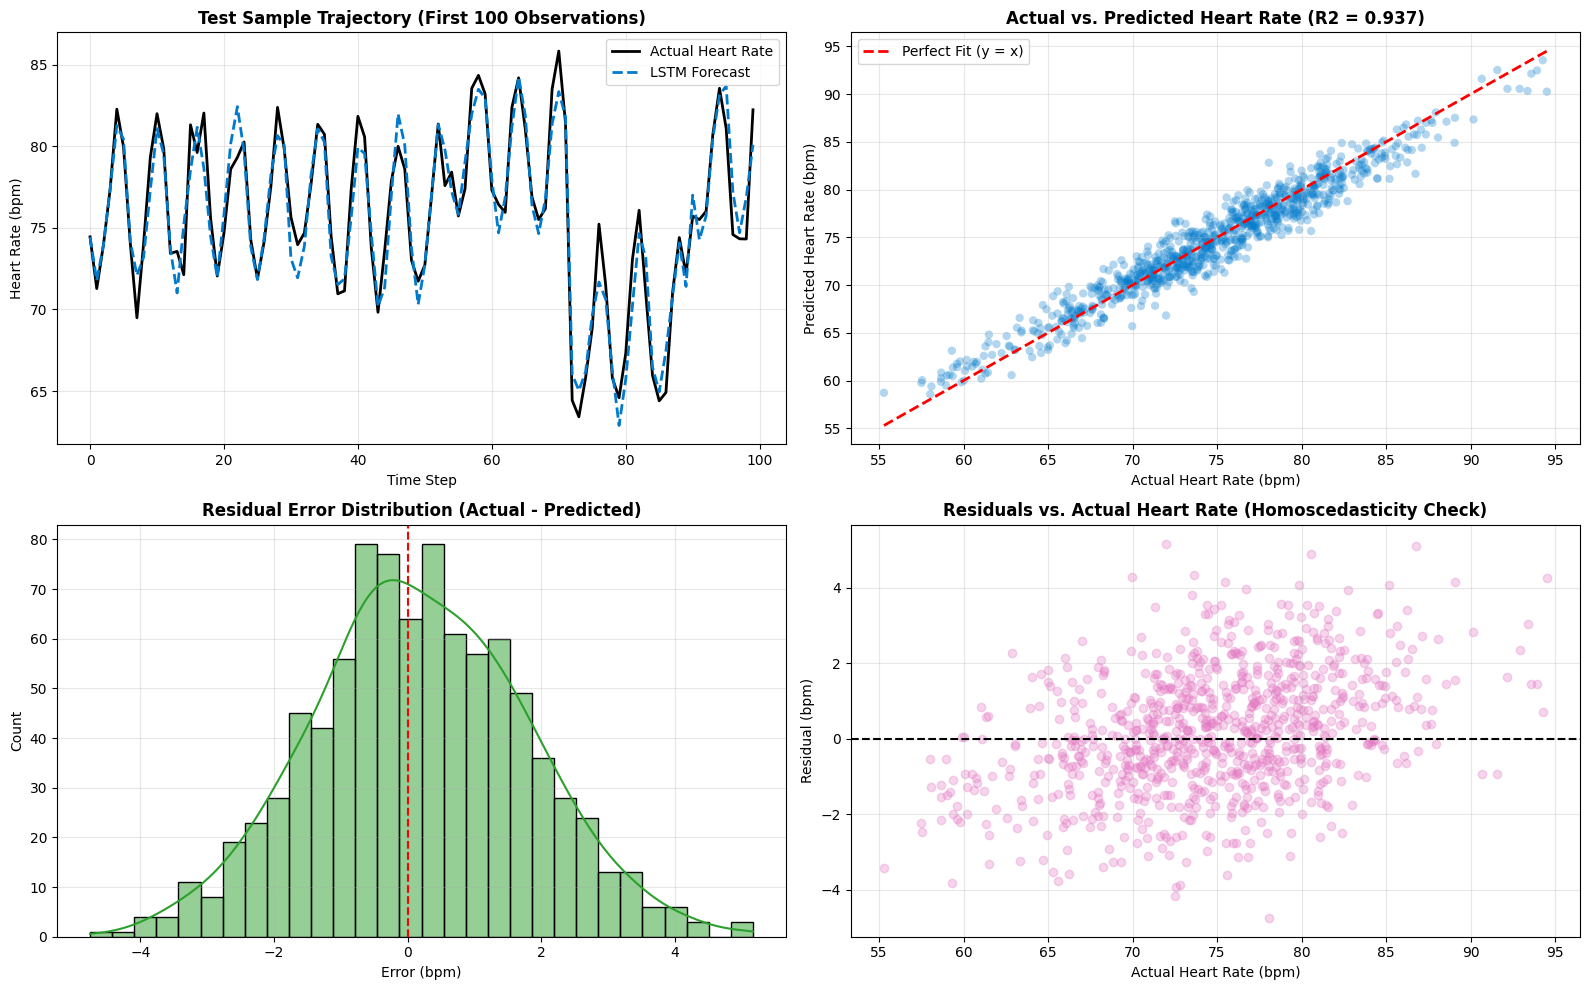

In [9]:
# 9. Visual Diagnostics: Trajectory, Correlation, & Residuals
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Trajectory for 100 consecutive test steps
axes[0, 0].plot(y_test_actual[:100], label='Actual Heart Rate', color='black', lw=2)
axes[0, 0].plot(y_pred_actual[:100], label='LSTM Forecast', color='#007acc', linestyle='--', lw=2)
axes[0, 0].set_title('Test Sample Trajectory (First 100 Observations)', fontweight='bold')
axes[0, 0].set_xlabel('Time Step')
axes[0, 0].set_ylabel('Heart Rate (bpm)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Scatter Actual vs Predicted
axes[0, 1].scatter(y_test_actual, y_pred_actual, alpha=0.3, color='#007acc', edgecolor='none')
min_val = min(y_test_actual.min(), y_pred_actual.min())
max_val = max(y_test_actual.max(), y_pred_actual.max())
axes[0, 1].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Perfect Fit (y = x)')
axes[0, 1].set_title(f'Actual vs. Predicted Heart Rate (R2 = {r2_lstm:.3f})', fontweight='bold')
axes[0, 1].set_xlabel('Actual Heart Rate (bpm)')
axes[0, 1].set_ylabel('Predicted Heart Rate (bpm)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Residual Error Distribution
residuals = y_test_actual - y_pred_actual
sns.histplot(residuals, kde=True, ax=axes[1, 0], color='#2ca02c', bins=30)
axes[1, 0].axvline(0, color='red', linestyle='--')
axes[1, 0].set_title('Residual Error Distribution (Actual - Predicted)', fontweight='bold')
axes[1, 0].set_xlabel('Error (bpm)')
axes[1, 0].grid(True, alpha=0.3)

# 4. Error by Prediction Magnitude
axes[1, 1].scatter(y_test_actual, residuals, alpha=0.3, color='#e377c2')
axes[1, 1].axhline(0, color='black', linestyle='--')
axes[1, 1].set_title('Residuals vs. Actual Heart Rate (Homoscedasticity Check)', fontweight='bold')
axes[1, 1].set_xlabel('Actual Heart Rate (bpm)')
axes[1, 1].set_ylabel('Residual (bpm)')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Interactive Real-Time Prediction Function

This function simulates production hospital deployment: given any patient's most recent 6 readings (last 24 hours), it pre-processes the vitals, runs LSTM inference, and outputs the forecasted heart rate 4 hours ahead.

In [10]:
# 10. Clinical Inference Function
def predict_next_heart_rate(recent_records_df, model, feat_scaler, tgt_scaler, lookback=6):
    assert len(recent_records_df) >= lookback, f"Must provide at least {lookback} readings."

    # Extract the last `lookback` readings
    latest_window = recent_records_df[feature_cols].tail(lookback)

    # Scale features
    window_scaled = feat_scaler.transform(latest_window)
    model_input = window_scaled.reshape(1, lookback, len(feature_cols))

    # Predict & Inverse Transform
    pred_scaled = model.predict(model_input, verbose=0)
    pred_bpm = tgt_scaler.inverse_transform(pred_scaled)[0][0]

    last_known_hr = latest_window['Heart_Rate'].iloc[-1]
    expected_delta = pred_bpm - last_known_hr

    return {
        "last_recorded_hr": round(float(last_known_hr), 2),
        "forecasted_hr_next_step": round(float(pred_bpm), 2),
        "predicted_delta": round(float(expected_delta), 2),
        "trend": "Rising" if expected_delta > 1.0 else ("Falling" if expected_delta < -1.0 else "Stable")
    }

# Test on the last patient
sample_patient = df[df['Patient_ID'] == df['Patient_ID'].iloc[-1]]
result = predict_next_heart_rate(sample_patient, model, feature_scaler, target_scaler, lookback=LOOKBACK)

print("Real-Time Patient Vitals Forecast:")
print(f"  * Last Recorded Heart Rate: {result['last_recorded_hr']} bpm")
print(f"  * Forecasted Next Heart Rate: {result['forecasted_hr_next_step']} bpm ({result['trend']}, delta: {result['predicted_delta']:+} bpm)")

Real-Time Patient Vitals Forecast:
  * Last Recorded Heart Rate: 77.86 bpm
  * Forecasted Next Heart Rate: 73.8 bpm (Falling, delta: -4.06 bpm)


In [11]:
# 11. Artifact Persistence
# Save Model and Scalers
model.save("patient_health_lstm_model.keras")
joblib.dump(feature_scaler, "patient_feature_scaler.pkl")
joblib.dump(target_scaler, "patient_target_scaler.pkl")

# Save detailed predictions CSV
forecast_summary = pd.DataFrame({
    'Actual_Heart_Rate': y_test_actual,
    'LSTM_Predicted_Heart_Rate': y_pred_actual,
    'Naive_Baseline_Heart_Rate': naive_pred,
    'Absolute_Error_LSTM': np.abs(y_test_actual - y_pred_actual)
})
forecast_summary.to_csv("patient_forecast_results.csv", index=False)

print("All artifacts successfully exported:")
print("  - patient_health_lstm_model.keras (Trained model)")
print("  - patient_feature_scaler.pkl (Input feature scaler)")
print("  - patient_target_scaler.pkl (Heart Rate target scaler)")
print("  - patient_forecast_results.csv (Evaluation dataset)")

All artifacts successfully exported:
  - patient_health_lstm_model.keras (Trained model)
  - patient_feature_scaler.pkl (Input feature scaler)
  - patient_target_scaler.pkl (Heart Rate target scaler)
  - patient_forecast_results.csv (Evaluation dataset)


In [12]:
# Feed any patient's latest 6 readings:
result = predict_next_heart_rate(sample_patient, model, feature_scaler, target_scaler)
print(result)

{'last_recorded_hr': 77.86, 'forecasted_hr_next_step': 73.8, 'predicted_delta': -4.06, 'trend': 'Falling'}
